<a href="https://colab.research.google.com/github/Erilocshada/erilocshada-PCVK-2026-course/blob/main/18_P10_244107020064.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **CELL IDENTITAS**

In [1]:
NAMA = 'Muhammad Pearl Ocshada'
NIM = '244107020064'
print(NAMA, NIM)

Muhammad Pearl Ocshada 244107020064


***Mount Drive & Persiapan Library***

> **Catatan:** upload folder `Images Object Detection` (termasuk `prabowo.jpg`) dan folder `Images/facedet` + `Images/haarcascades` dari Drive link modul ke Google Drive Anda pada path `/MyDrive/PCVK/` sebelum menjalankan notebook ini.

In [4]:
import os
import cv2
import time
import random
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import as_strided
from google.colab import drive

drive.mount('/content/drive')

BASE    = '/content/drive/MyDrive/PCVK/Images Object Detection/'
FACEDET = '/content/drive/MyDrive/PCVK/Images/facedet/'
HAAR    = '/content/drive/MyDrive/PCVK/Images/haarcascades/'

print('Isi folder BASE:', sorted(os.listdir(BASE)))

Mounted at /content/drive
Isi folder BASE: ['KTM.jpg', 'animal-template.jpg', 'animal.jpg', 'bahrain-template.jpg', 'bahrain.jpg', 'car-park.jpg', 'cat-and-rabbit.jpg', 'cat-template.jpg', 'cat2_templatejpg.jpg', 'cats_and_bunnies.jpg', 'chess-board.jpg', 'laptop.jpg', 'parking-lot-cars.jpg', 'prabowo.jpg', 'sudoku.jpg']


## D1. Praktikum Deteksi Obyek Dasar
### **2. Template Matching 6 Metode OpenCV**
Citra masukan: `cats_and_bunnies.jpg`, template: `cat2_templatejpg.jpg`.

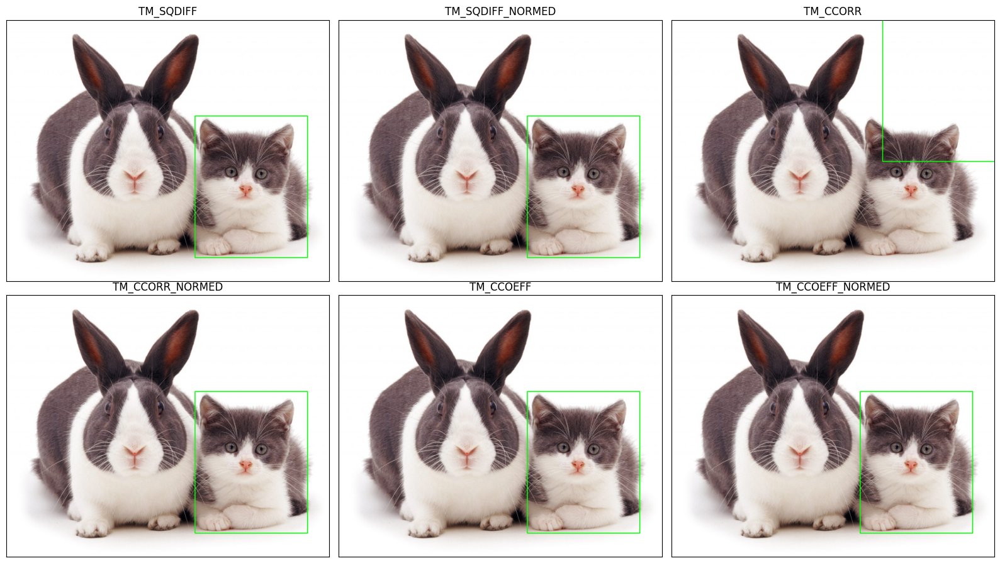

In [5]:
img  = cv2.imread(BASE + 'cats_and_bunnies.jpg')
temp = cv2.imread(BASE + 'cat2_templatejpg.jpg', 0)
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

methods = ['TM_SQDIFF', 'TM_SQDIFF_NORMED', 'TM_CCORR',
           'TM_CCORR_NORMED', 'TM_CCOEFF', 'TM_CCOEFF_NORMED']

tw, th = temp.shape[1], temp.shape[0]
plt.figure(figsize=(16, 9))
for i, m in enumerate(methods):
    res = cv2.matchTemplate(img_gray, temp, getattr(cv2, m))
    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)
    if m in ['TM_SQDIFF', 'TM_SQDIFF_NORMED']:
        top_left = min_loc
    else:
        top_left = max_loc
    bottom_right = (top_left[0] + tw, top_left[1] + th)

    canvas = img.copy()
    cv2.rectangle(canvas, top_left, bottom_right, (0, 255, 0), 2)
    plt.subplot(2, 3, i + 1)
    plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    plt.title(m)
    plt.xticks([]); plt.yticks([])
plt.tight_layout()
plt.show()

### **3. Template Matching Tanpa OpenCV (Multiple Object)**
Citra masukan: `bahrain.jpg`, template: `bahrain-template.jpg`. Korelasi koefisien normalisasi (NCC) dihitung manual dengan NumPy (tanpa `cv2.matchTemplate`). Karena objek-objek pada citra muncul dalam berbagai rotasi, template diputar pada beberapa sudut dan diambil skor kecocokan terbaik per lokasi, lalu semua puncak di atas threshold diambil (multi-objek).

Jumlah objek terdeteksi: 8


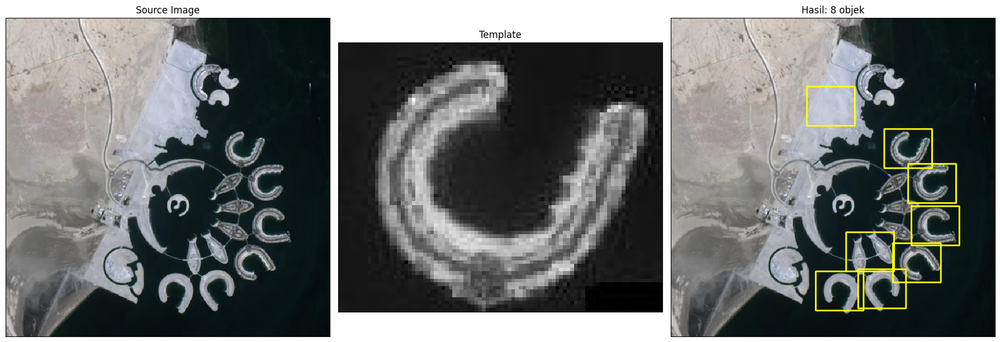

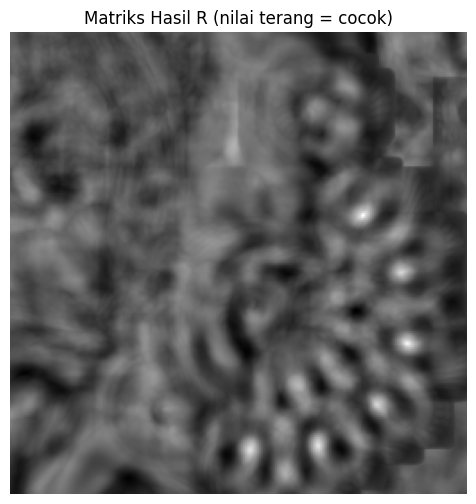

In [6]:
def manual_ncc(src, tpl):
    """Normalized cross-correlation tanpa cv2.matchTemplate."""
    src = src.astype(np.float64)
    tpl = tpl.astype(np.float64)
    sh, sw = src.shape
    th, tw = tpl.shape
    t = tpl.ravel()
    tc = t - t.mean()
    tc_norm = np.sqrt((tc ** 2).sum())
    R = np.zeros((sh - th + 1, sw - tw + 1))
    for i in range(R.shape[0]):
        patches = as_strided(
            src[i:i + th],
            shape=(sw - tw + 1, th, tw),
            strides=(src.strides[1], src.strides[0], src.strides[1])
        ).reshape(sw - tw + 1, -1)
        pc = patches - patches.mean(axis=1, keepdims=True)
        num = pc @ tc
        den = np.sqrt((pc ** 2).sum(axis=1)) * tc_norm
        R[i] = num / np.where(den == 0, 1, den)
    return R


def find_matches(R, tpl_shape, thr=0.55):
    """Ambil semua puncak kecocokan di atas threshold (non-max suppression sederhana)."""
    th, tw = tpl_shape
    ys, xs = np.where(R >= thr)
    pts = sorted(zip(R[ys, xs], ys, xs), reverse=True)
    boxes = []
    for val, y, x in pts:
        if all(abs(y - by) > th * 0.7 or abs(x - bx) > tw * 0.7 for _, by, bx in boxes):
            boxes.append((val, y, x))
    return boxes


src_bahrain = cv2.imread(BASE + 'bahrain.jpg')
tpl_bahrain = cv2.imread(BASE + 'bahrain-template.jpg', 0)
src_gray    = cv2.cvtColor(src_bahrain, cv2.COLOR_BGR2GRAY)

# turunkan skala agar perhitungan manual tidak terlalu lama
SCALE = 0.5
src_s = cv2.resize(src_gray, None, fx=SCALE, fy=SCALE)
tpl_s = cv2.resize(tpl_bahrain, None, fx=SCALE, fy=SCALE)
th, tw = tpl_s.shape

# putar template pada beberapa sudut, simpan skor terbaik per lokasi
best_R = None
for angle in range(0, 360, 15):
    M = cv2.getRotationMatrix2D((tw / 2, th / 2), angle, 1.0)
    rot = cv2.warpAffine(tpl_s, M, (tw, th))
    R = manual_ncc(src_s, rot)
    best_R = R if best_R is None else np.maximum(best_R, R)

matches = find_matches(best_R, (th, tw), thr=0.55)
print('Jumlah objek terdeteksi:', len(matches))

hasil = src_bahrain.copy()
for val, y, x in matches:
    x, y = int(x / SCALE), int(y / SCALE)
    w, h = int(tw / SCALE), int(th / SCALE)
    cv2.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 255), 2)  # kuning

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(cv2.cvtColor(src_bahrain, cv2.COLOR_BGR2RGB)); axes[0].set_title('Source Image')
axes[1].imshow(tpl_bahrain, cmap='gray'); axes[1].set_title('Template')
axes[2].imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)); axes[2].set_title(f'Hasil: {len(matches)} objek')
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 6))
plt.imshow(best_R, cmap='gray')
plt.title('Matriks Hasil R (nilai terang = cocok)')
plt.axis('off')
plt.show()

### **4. Edge Detection pada `car-park.jpg`**
#### a. Sobel Edge Detection

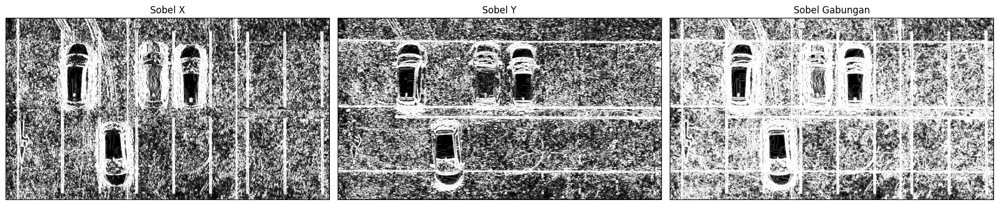

In [7]:
img_cp = cv2.imread(BASE + 'car-park.jpg', 0)

sobelx  = cv2.Sobel(img_cp, cv2.CV_64F, 1, 0, ksize=5)
sobely  = cv2.Sobel(img_cp, cv2.CV_64F, 0, 1, ksize=5)
sobelxy = cv2.magnitude(sobelx, sobely)
sobelxy = np.uint8(np.clip(sobelxy, 0, 255))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(np.uint8(np.clip(np.abs(sobelx), 0, 255)), cmap='gray'); axes[0].set_title('Sobel X')
axes[1].imshow(np.uint8(np.clip(np.abs(sobely), 0, 255)), cmap='gray'); axes[1].set_title('Sobel Y')
axes[2].imshow(sobelxy, cmap='gray'); axes[2].set_title('Sobel Gabungan')
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

#### b. Canny Edge Detection

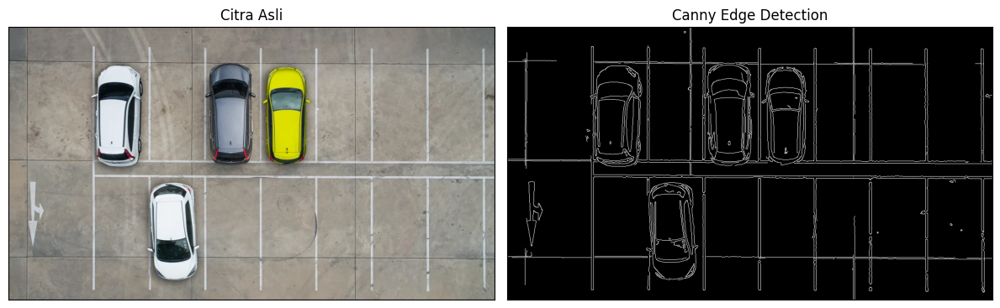

In [8]:
img_cp_color = cv2.imread(BASE + 'car-park.jpg')
blurred = cv2.GaussianBlur(img_cp, (5, 5), 0)
canny = cv2.Canny(blurred, 60, 150)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_cp_color, cv2.COLOR_BGR2RGB))
plt.title('Citra Asli'); plt.xticks([]); plt.yticks([])
plt.subplot(1, 2, 2)
plt.imshow(canny, cmap='gray')
plt.title('Canny Edge Detection'); plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()

#### c. Laplacian Edge Detection

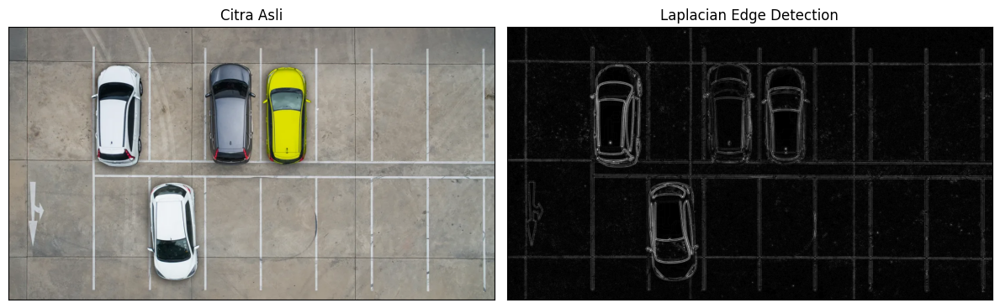

In [9]:
lap = cv2.Laplacian(blurred, cv2.CV_64F)
lap = np.uint8(np.clip(np.abs(lap), 0, 255))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_cp_color, cv2.COLOR_BGR2RGB))
plt.title('Citra Asli'); plt.xticks([]); plt.yticks([])
plt.subplot(1, 2, 2)
plt.imshow(lap, cmap='gray')
plt.title('Laplacian Edge Detection'); plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()

### **5. Corner Detection pada `chess-board.jpg`**
#### a. Harris Corner Detection

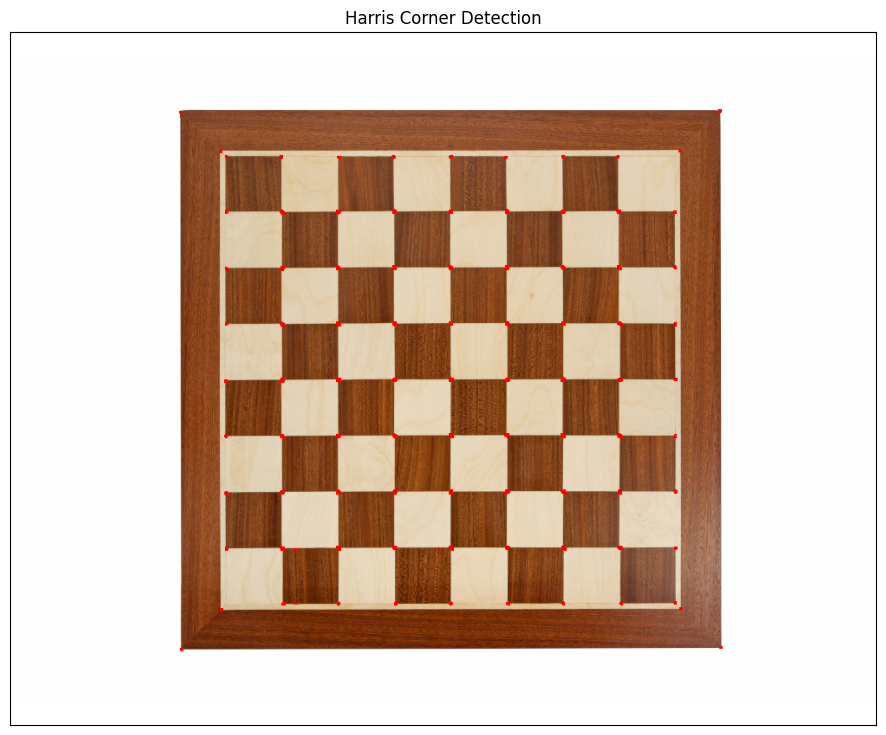

In [10]:
chess = cv2.imread(BASE + 'chess-board.jpg')
chess_gray = cv2.cvtColor(chess, cv2.COLOR_BGR2GRAY)
chess_gray32 = np.float32(chess_gray)

dst = cv2.cornerHarris(chess_gray32, blockSize=2, ksize=3, k=0.04)
dst = cv2.dilate(dst, None)
harris_result = chess.copy()
harris_result[dst > 0.01 * dst.max()] = [0, 0, 255]

plt.figure(figsize=(12, 9))
plt.imshow(cv2.cvtColor(harris_result, cv2.COLOR_BGR2RGB))
plt.title('Harris Corner Detection')
plt.xticks([]); plt.yticks([])
plt.show()

#### b. Shi-Tomasi (Good Features to Track)

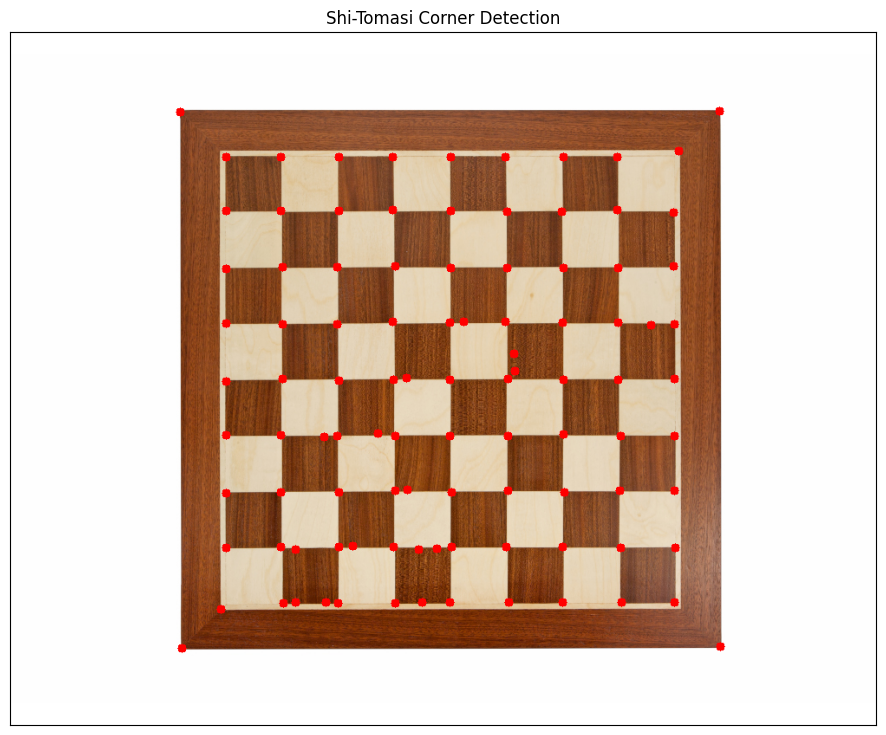

In [12]:
corners = cv2.goodFeaturesToTrack(chess_gray, maxCorners=100,
                                  qualityLevel=0.01, minDistance=10)
corners = np.intp(corners)

shitomasi_result = chess.copy()
for c in corners:
    x, y = c.ravel()
    cv2.circle(shitomasi_result, (x, y), 5, (0, 0, 255), -1)

plt.figure(figsize=(12, 9))
plt.imshow(cv2.cvtColor(shitomasi_result, cv2.COLOR_BGR2RGB))
plt.title('Shi-Tomasi Corner Detection')
plt.xticks([]); plt.yticks([])
plt.show()

### **6. Hough Transform (Grid Detection) pada `sudoku.jpg`**

Jumlah garis terdeteksi: 246


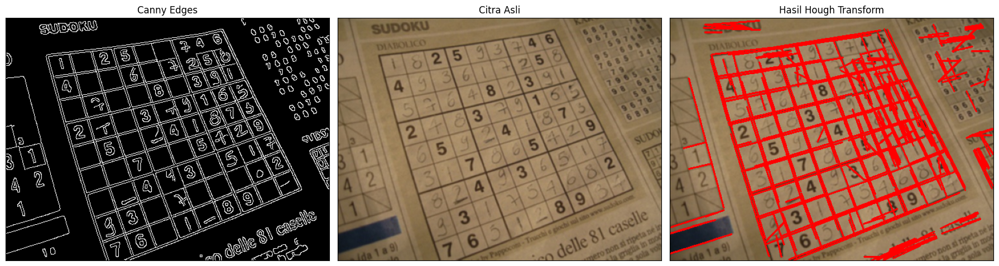

In [15]:
sudoku = cv2.imread(BASE + 'sudoku.jpg')
sudoku_gray = cv2.cvtColor(sudoku, cv2.COLOR_BGR2GRAY)
sudoku_blur = cv2.GaussianBlur(sudoku_gray, (3, 3), 0)
edges = cv2.Canny(sudoku_blur, 50, 150)

lines = cv2.HoughLinesP(edges, rho=1, theta=np.pi / 180, threshold=40,
                        minLineLength=25, maxLineGap=8)

hough_result = sudoku.copy()
if lines is not None:
    print('Jumlah garis terdeteksi:', len(lines))
    for line in lines:
        # Gunakan ravel() untuk meratakan koordinat secara aman menjadi 4 elemen
        x1, y1, x2, y2 = line.ravel()
        cv2.line(hough_result, (x1, y1), (x2, y2), (0, 0, 255), 2)
else:
    print('Tidak ada garis yang terdeteksi.')

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(edges, cmap='gray'); axes[0].set_title('Canny Edges')
axes[1].imshow(cv2.cvtColor(sudoku, cv2.COLOR_BGR2RGB)); axes[1].set_title('Citra Asli')
axes[2].imshow(cv2.cvtColor(hough_result, cv2.COLOR_BGR2RGB)); axes[2].set_title('Hasil Hough Transform')
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### **7. Contour Detection dengan `findContours()` pada `laptop.jpg`**

Jumlah contour: 30


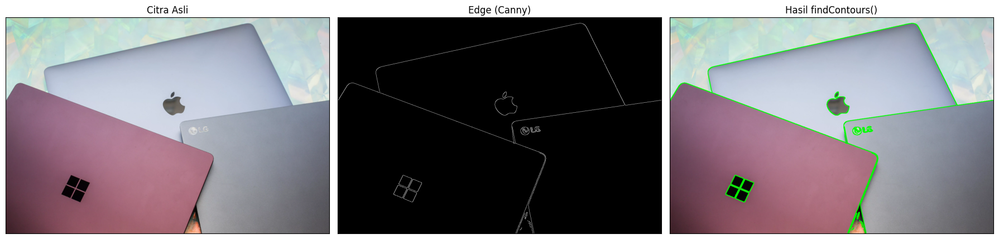

In [16]:
laptop = cv2.imread(BASE + 'laptop.jpg')
laptop_small = cv2.resize(laptop, (laptop.shape[1] // 3, laptop.shape[0] // 3))
laptop_gray = cv2.cvtColor(laptop_small, cv2.COLOR_BGR2GRAY)
laptop_blur = cv2.GaussianBlur(laptop_gray, (5, 5), 0)
edge = cv2.Canny(laptop_blur, 30, 120)

contours, hierarchy = cv2.findContours(edge, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
print('Jumlah contour:', len(contours))

contour_img = laptop_small.copy()
cv2.drawContours(contour_img, contours, -1, (0, 255, 0), 2)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(cv2.cvtColor(laptop_small, cv2.COLOR_BGR2RGB)); axes[0].set_title('Citra Asli')
axes[1].imshow(edge, cmap='gray'); axes[1].set_title('Edge (Canny)')
axes[2].imshow(cv2.cvtColor(contour_img, cv2.COLOR_BGR2RGB)); axes[2].set_title('Hasil findContours()')
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## D2. Praktikum Feature Matching dan Face Detection
### **8. Face Detection pada Image Object `/images/facedet`**
Menggunakan `haarcascade_frontalface_alt.xml` dan `detectMultiScale()`.

OpenCV successfully initialized. Version: 5.0.0


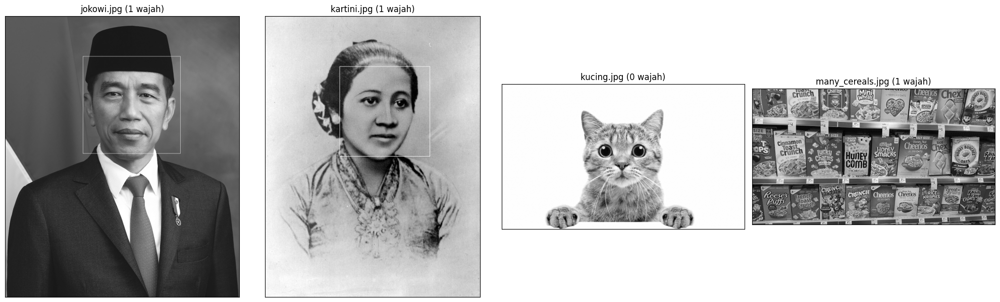

In [1]:
import sys
import os
import matplotlib.pyplot as plt
import cv2

# Mendefinisikan kembali variabel path karena kernel baru saja di-restart
BASE    = '/content/drive/MyDrive/PCVK/Images Object Detection/'
FACEDET = '/content/drive/MyDrive/PCVK/Images/facedet/'
HAAR    = '/content/drive/MyDrive/PCVK/Images/haarcascades/'

print("OpenCV successfully initialized. Version:", cv2.__version__)

# Memastikan cascade classifier ter-load dengan benar
cascade_wajah = cv2.CascadeClassifier(HAAR + 'haarcascade_frontalface_alt.xml')
if cascade_wajah.empty():
    cascade_wajah = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_alt.xml')

folder = FACEDET if os.path.isdir(FACEDET) else BASE
images = [f for f in sorted(os.listdir(folder))
          if f.lower().endswith(('.jpg', '.png')) and 'template' not in f.lower()]

fig, axes = plt.subplots(1, min(len(images), 4), figsize=(20, 6))
if len(images) == 1:
    axes = [axes]
for ax, fname in zip(axes, images[:4]):
    img_fd = cv2.imread(folder + fname, 0)
    roi_wajah = cascade_wajah.detectMultiScale(img_fd, scaleFactor=1.1, minNeighbors=4)
    for (x, y, w, h) in roi_wajah:
        cv2.rectangle(img_fd, (x, y), (x + w, y + h), (255, 255, 255), 1)
    ax.imshow(img_fd, cmap='gray')
    ax.set_title(f'{fname} ({len(roi_wajah)} wajah)')
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### **9. Deteksi Wajah Kucing**
OpenCV menyediakan pretrained cascade untuk kucing: `haarcascade_frontalcatface_extended.xml`. File ini diunduh langsung dari repository resmi OpenCV.

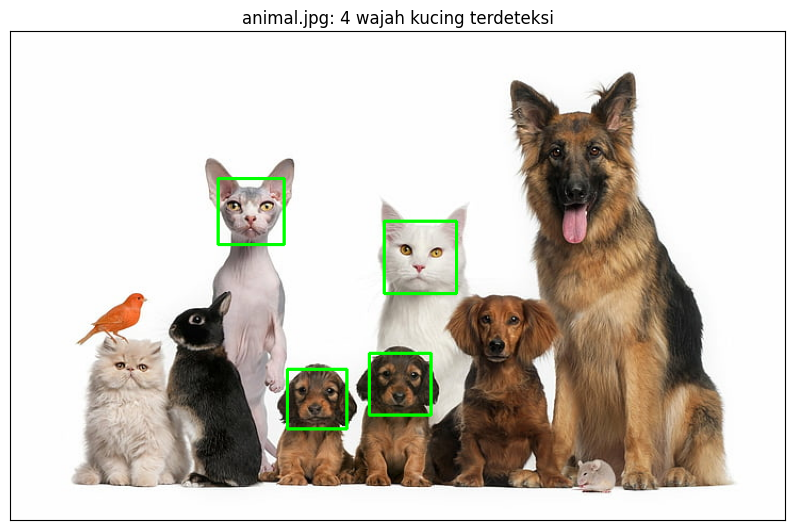

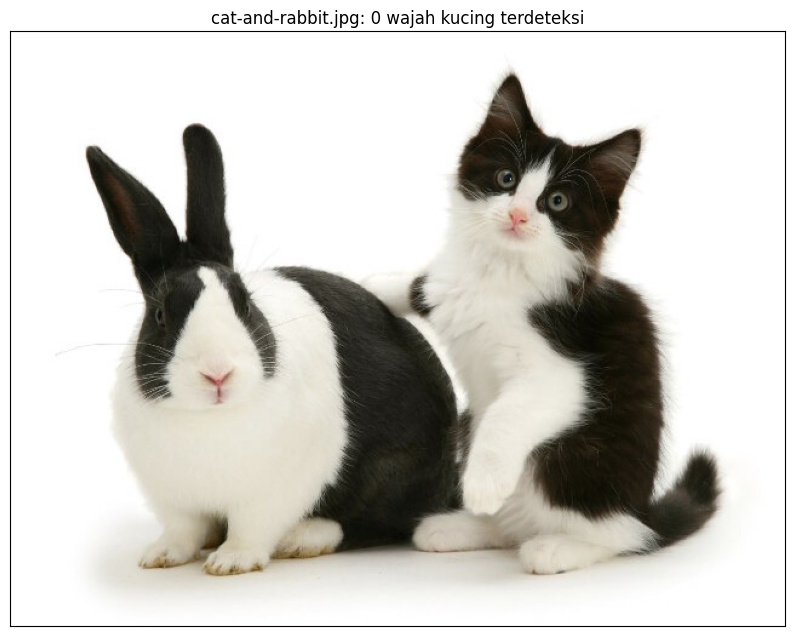

In [2]:
import urllib.request

cat_xml = '/content/haarcascade_frontalcatface_extended.xml'
if not os.path.exists(cat_xml):
    url = ('https://raw.githubusercontent.com/opencv/opencv/master/'
           'data/haarcascades/haarcascade_frontalcatface_extended.xml')
    urllib.request.urlretrieve(url, cat_xml)

cascade_kucing = cv2.CascadeClassifier(cat_xml)

for fname in ['animal.jpg', 'cat-and-rabbit.jpg']:
    img_kucing = cv2.imread(BASE + fname)
    gray_kucing = cv2.cvtColor(img_kucing, cv2.COLOR_BGR2GRAY)
    faces = cascade_kucing.detectMultiScale(gray_kucing, scaleFactor=1.1, minNeighbors=4)
    for (x, y, w, h) in faces:
        cv2.rectangle(img_kucing, (x, y), (x + w, y + h), (0, 255, 0), 2)
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(img_kucing, cv2.COLOR_BGR2RGB))
    plt.title(f'{fname}: {len(faces)} wajah kucing terdeteksi')
    plt.xticks([]); plt.yticks([])
    plt.show()

### **10. Eyes Detection pada Wajah Pak Prabowo**

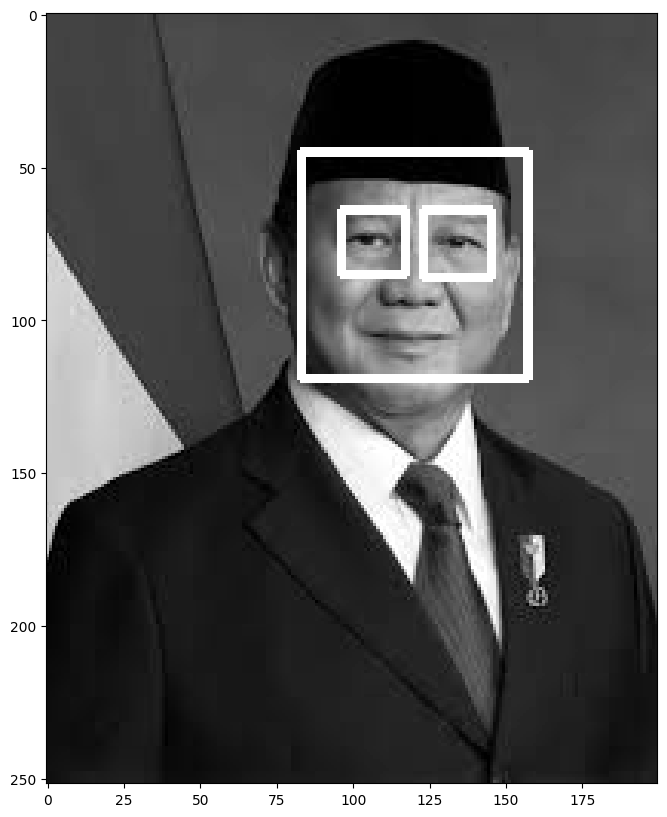

In [8]:
cascade_wajah = cv2.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/haarcascades/haarcascade_frontalface_alt.xml')
cascade_mata = cv2.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/haarcascades/haarcascade_eye.xml')

prabowo = cv2.imread('/content/drive/MyDrive/PCVK/Images Object Detection/prabowo.jpg', 0)
faces = cascade_wajah.detectMultiScale(prabowo, 1.3, 5)

for (x, y, w, h) in faces:
    cv2.rectangle(prabowo, (x, y), (x + w, y + h), (255, 255, 255), 2)
    roi_gray = prabowo[y:y + h, x:x + w]
    eyes = cascade_mata.detectMultiScale(roi_gray)
    for (ex, ey, ew, eh) in eyes:
        cv2.rectangle(roi_gray, (ex, ey), (ex + ew, ey + eh), (255, 255, 255), 2)

plt.figure(figsize=(10, 10))
plt.imshow(prabowo, cmap='gray')
plt.show()

### **11. Smile Detection pada Gambar `people`**

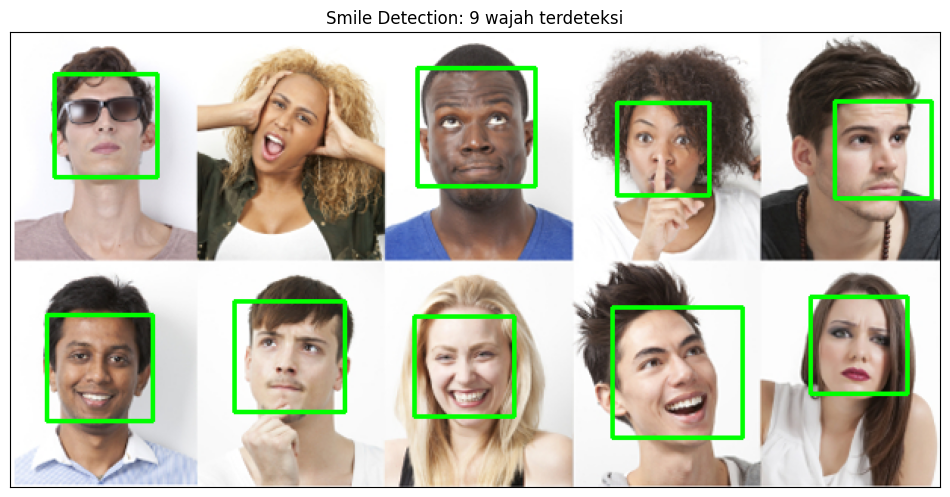

In [9]:
people_path = None
for cand in [FACEDET + 'people.jpg', FACEDET + 'people.png', BASE + 'people.jpg']:
    if os.path.exists(cand):
        people_path = cand
        break

if people_path is None:
    print('Gambar people tidak ditemukan. Download folder facedet dari link modul '
          '(https://drive.google.com/drive/folders/1M30vcqgPBD1PHQpqFUtxWdtiMrwSpijC) '
          'ke /MyDrive/PCVK/Images/facedet/ lalu jalankan cell ini lagi.')
else:
    people = cv2.imread(people_path)
    people_gray = cv2.cvtColor(people, cv2.COLOR_BGR2GRAY)

    cascade_senyum = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_smile.xml')
    faces = cascade_wajah.detectMultiScale(people_gray, scaleFactor=1.1, minNeighbors=5)
    for (x, y, w, h) in faces:
        cv2.rectangle(people, (x, y), (x + w, y + h), (0, 255, 0), 2)
        roi_gray = people_gray[y:y + h, x:x + w]
        roi_color = people[y:y + h, x:x + w]
        senyum = cascade_senyum.detectMultiScale(roi_gray, scaleFactor=1.5, minNeighbors=50)
        for (sx, sy, sw, sh) in senyum:
            cv2.rectangle(roi_color, (sx, sy), (sx + sw, sy + sh), (255, 0, 0), 2)

    plt.figure(figsize=(12, 10))
    plt.imshow(cv2.cvtColor(people, cv2.COLOR_BGR2RGB))
    plt.title(f'Smile Detection: {len(faces)} wajah terdeteksi')
    plt.xticks([]); plt.yticks([])
    plt.show()

### **12. Face Tracking dengan Kamera di Google Colab**
Jalankan cell di bawah, izinkan akses kamera saat browser meminta izin, lalu tekan tombol **Use camera** untuk menangkap frame secara berulang. Hentikan dengan `Kernel > Interrupt`.

array([[[218, 228, 229],
        [221, 231, 232],
        [226, 236, 237],
        ...,
        [238, 226, 214],
        [237, 225, 213],
        [236, 224, 212]],

       [[220, 230, 231],
        [223, 233, 234],
        [228, 238, 239],
        ...,
        [238, 226, 214],
        [237, 225, 213],
        [236, 224, 212]],

       [[224, 233, 232],
        [227, 236, 235],
        [231, 240, 239],
        ...,
        [237, 225, 213],
        [236, 224, 212],
        [235, 223, 211]],

       ...,

       [[ 85,  47,  28],
        [ 83,  45,  26],
        [ 81,  43,  24],
        ...,
        [197, 182, 153],
        [198, 182, 156],
        [200, 184, 158]],

       [[ 88,  50,  29],
        [ 86,  48,  27],
        [ 85,  44,  24],
        ...,
        [196, 181, 152],
        [198, 183, 154],
        [199, 184, 155]],

       [[ 90,  52,  31],
        [ 87,  49,  28],
        [ 86,  45,  25],
        ...,
        [195, 180, 151],
        [197, 182, 153],
        [198, 183, 154]]], shape=(480, 640, 3), dtype=uint8)
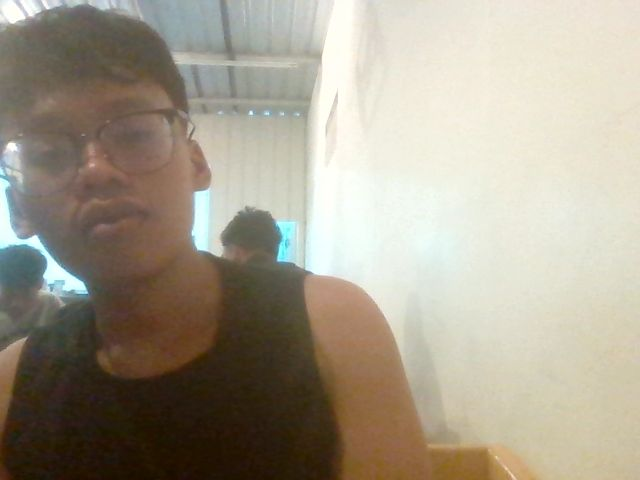

Face tracking dihentikan.


In [13]:
from google.colab.output import eval_js
from base64 import b64decode
from IPython.display import display, clear_output
import cv2
import time

def take_photo(filename='/content/photo.jpg', quality=0.8):
    js = '''
    (async function() {
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      const video = document.createElement('video');
      video.srcObject = stream;
      await video.play();
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      video.remove();
      return canvas.toDataURL('image/jpeg', ''' + str(quality) + ''');
    })()
    '''
    data_url = eval_js(js)
    binary = b64decode(data_url.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

cascade_tracking = cascade_wajah
try:
    while True:
        take_photo()
        frame = cv2.imread('/content/photo.jpg')
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        faces = cascade_tracking.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)
        for (x, y, w, h) in faces:
            cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 3)
        clear_output(wait=True)
        display(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        time.sleep(0.5)
except KeyboardInterrupt:
    print('Face tracking dihentikan.')

### **13. Blurring pada Wajah yang Terdeteksi**
Menggunakan `cv2.medianBlur` (contoh pada wajah Pak Prabowo).

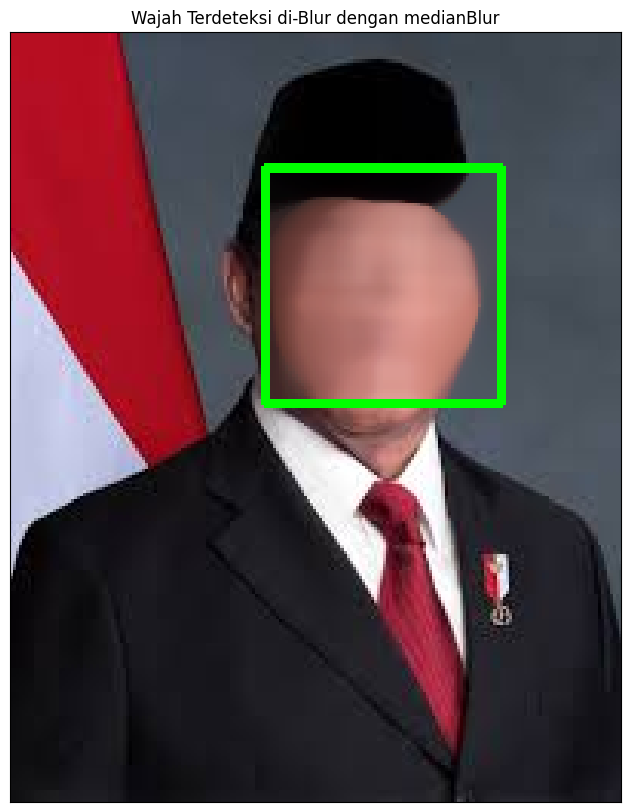

In [14]:
blur_img = cv2.imread(BASE + 'prabowo.jpg')
blur_gray = cv2.cvtColor(blur_img, cv2.COLOR_BGR2GRAY)

faces = cascade_wajah.detectMultiScale(blur_gray, scaleFactor=1.1, minNeighbors=5)
for (x, y, w, h) in faces:
    roi = blur_img[y:y + h, x:x + w]
    roi_blur = cv2.medianBlur(roi, 25)
    blur_img[y:y + h, x:x + w] = roi_blur
    cv2.rectangle(blur_img, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(blur_img, cv2.COLOR_BGR2RGB))
plt.title('Wajah Terdeteksi di-Blur dengan medianBlur')
plt.xticks([]); plt.yticks([])
plt.show()

### **14. Mengolah Gambar KTM**
#### a & b. Tampilkan KTM

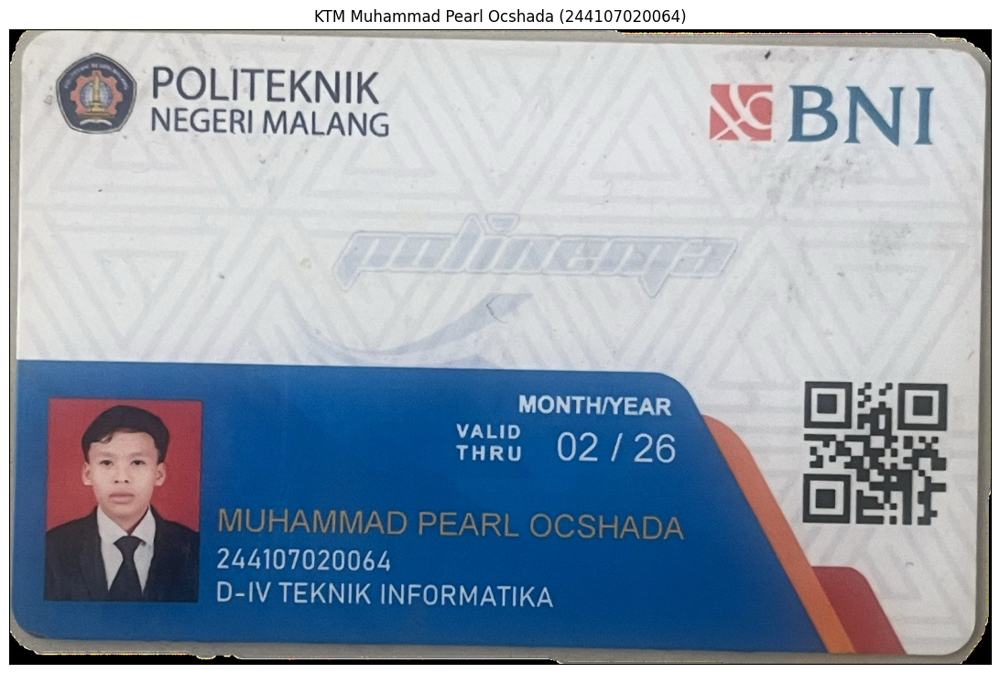

In [16]:
if 'NAMA' not in globals():
    NAMA = 'Muhammad Pearl Ocshada'
if 'NIM' not in globals():
    NIM = '244107020064'

ktm = cv2.imread(BASE + 'KTM.jpg')
plt.figure(figsize=(14, 9))
plt.imshow(cv2.cvtColor(ktm, cv2.COLOR_BGR2RGB))
plt.title(f'KTM {NAMA} ({NIM})')
plt.xticks([]); plt.yticks([])
plt.show()

#### c. Deteksi Obyek KTM pada Gambar yang Berisi KTM Bersama Barang Lain (Feature Matching)
Scene dibuat dengan menempelkan KTM pada foto laptop di atas meja. Deteksi dilakukan dengan **SIFT + ratio test + homography**, sehingga KTM ditemukan meski berubah skala/rotasi.

> Ganti `scene` dengan foto KTM asli bersama barang lain bila Anda memfotonya sendiri.

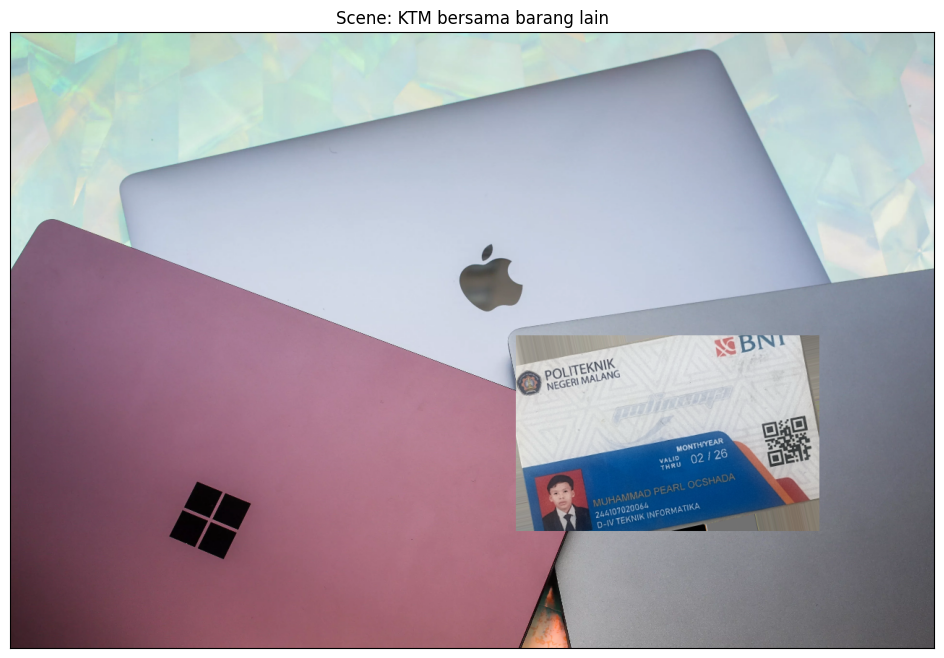

Match bagus: 404


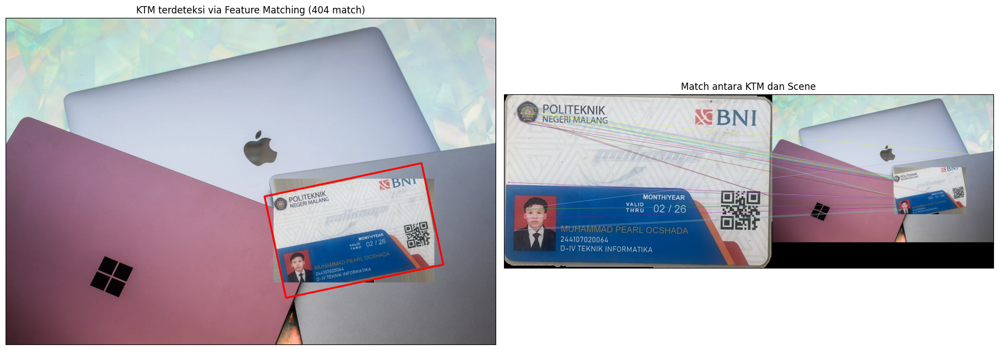

In [19]:
import numpy as np

# --- Membuat scene: KTM bersama barang lain ---
bg = cv2.imread(BASE + 'laptop.jpg')
bg = cv2.resize(bg, (1280, 853))
ktm_small = cv2.resize(ktm, (420, int(420 * ktm.shape[0] / ktm.shape[1])))
M_rot = cv2.getRotationMatrix2D(
    (ktm_small.shape[1] / 2, ktm_small.shape[0] / 2), 12, 1.0)
ktm_rot = cv2.warpAffine(ktm_small, M_rot, ktm_small.shape[1::-1],
                         borderMode=cv2.BORDER_REPLICATE)
x0, y0 = 700, 420
scene = bg.copy()
scene[y0:y0 + ktm_rot.shape[0], x0:x0 + ktm_rot.shape[1]] = ktm_rot

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(scene, cv2.COLOR_BGR2RGB))
plt.title('Scene: KTM bersama barang lain')
plt.xticks([]); plt.yticks([])
plt.show()

# --- Feature matching SIFT ---
sift = cv2.SIFT_create(nfeatures=3000)
kp1, des1 = sift.detectAndCompute(ktm, None)
kp2, des2 = sift.detectAndCompute(scene, None)

bf = cv2.BFMatcher()
raw_matches = bf.knnMatch(des1, des2, k=2)
good = [m for m, n in raw_matches if m.distance < 0.7 * n.distance]
print('Match bagus:', len(good))

if len(good) >= 4:
    src_pts = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    h, w = ktm.shape[:2]
    corners = np.float32([[0, 0], [0, h - 1], [w - 1, h - 1], [w - 1, 0]]).reshape(-1, 1, 2)
    projected = cv2.perspectiveTransform(corners, H).astype(np.int32)
    result = scene.copy()
    cv2.polylines(result, [projected], True, (0, 0, 255), 4)

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    axes[0].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f'KTM terdeteksi via Feature Matching ({len(good)} match)')
    axes[0].set_xticks([]); axes[0].set_yticks([])
    match_img = cv2.drawMatches(ktm, kp1, scene, kp2, good[:30], None,
                                flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    axes[1].imshow(cv2.cvtColor(match_img, cv2.COLOR_BGR2RGB))
    axes[1].set_title('Match antara KTM dan Scene')
    axes[1].set_xticks([]); axes[1].set_yticks([])
    plt.tight_layout(); plt.show()
else:
    print('Match kurang dari 4, tingkatkan rasio threshold atau jumlah fitur.')

## D3. Tugas Pengayaan: Pengenalan Karakter KTM dengan CNN
#### Persiapan Dataset Training (karakter 0-9)
Data training dibuat di Colab: karakter 0-9 dirender dengan font digital lalu di-augmentasi (rotasi, skala, geser, blur) — mensimulasikan hasil cropping satu per satu pada image editor sesuai modul.

In [21]:
import random
import pickle
from tqdm import tqdm

DATADIR = '/content/dataset/training'
width, height = 100, 100

def render_char(ch, size=60):
    img = np.zeros((100, 100), dtype=np.uint8)
    (tw, th), _ = cv2.getTextSize(ch, cv2.FONT_HERSHEY_SIMPLEX, 2.0, 3)
    cv2.putText(img, ch, (50 - tw // 2, 50 + th // 2),
                cv2.FONT_HERSHEY_SIMPLEX, 2.0, 255, 3)
    return img

def augment(img, n=40):
    outs = []
    for _ in range(n):
        scale = random.uniform(0.7, 1.1)
        angle = random.uniform(-15, 15)
        M = cv2.getRotationMatrix2D((50, 50), angle, scale)
        M[0, 2] += random.uniform(-8, 8)
        M[1, 2] += random.uniform(-8, 8)
        out = cv2.warpAffine(img, M, (100, 100))
        out = cv2.GaussianBlur(out, (3, 3), random.uniform(0, 1.5))
        outs.append(out)
    return outs

os.makedirs(DATADIR, exist_ok=True)
for ch in '0123456789':
    path = os.path.join(DATADIR, ch)
    os.makedirs(path, exist_ok=True)
    base = render_char(ch)
    for i, aug in enumerate(augment(base, n=40)):
        cv2.imwrite(os.path.join(path, f'{i:03d}.png'), aug)
print('Dataset training siap:', sorted(os.listdir(DATADIR)))

Dataset training siap: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


#### Loop Data Training -> Pickle (sesuai kode modul)

In [22]:
dirs = sorted(os.listdir(DATADIR))
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open('/content/X.pickle', 'wb'))
pickle.dump(Y, open('/content/Y.pickle', 'wb'))
pickle.dump(dirs, open('/content/kelas.pickle', 'wb'))

print('jumlah data :', len(training_data))
print('jumlah kelas:', len(dirs), dirs)

9: 100%|██████████| 40/40 [00:00<00:00, 4872.28it/s]

jumlah data : 400
jumlah kelas: 10 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


#### Training Data (CNN)

In [23]:
import tensorflow as tf
from keras.layers import (Input, Conv2D, MaxPooling2D,
                          Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open('/content/X.pickle', 'rb'))
Y = pickle.load(open('/content/Y.pickle', 'rb'))

Y = to_categorical(Y)
X = X / 255.0
jumlah_kelas = Y.shape[1]

inputs     = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten   = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64,  activation='relu')(fc_layer)
outputs  = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('/content/anpr.keras')

print('akurasi training :', riwayat.history['accuracy'][-1])
print('akurasi validasi :', riwayat.history['val_accuracy'][-1])

Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 485ms/step - accuracy: 0.1000 - loss: 2.3003 - val_accuracy: 0.2000 - val_loss: 2.2899
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 677ms/step - accuracy: 0.2250 - loss: 2.2618 - val_accuracy: 0.2250 - val_loss: 2.2670
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 463ms/step - accuracy: 0.3187 - loss: 2.1956 - val_accuracy: 0.2125 - val_loss: 2.2300
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 530ms/step - accuracy: 0.3812 - loss: 2.0891 - val_accuracy: 0.3125 - val_loss: 2.1447
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 620ms/step - accuracy: 0.4688 - loss: 1.9045 - val_accuracy: 0.3750 - val_loss: 2.0158
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 459ms/step - accuracy: 0.5063 - loss: 1.6453 - val_accuracy: 0.4375 - val_loss: 1.8201
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 717ms/step - accuracy: 0.6000 - loss: 1.3616 - val_accuracy: 0.5125 - val_loss: 1.5736
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 506ms/step - accuracy: 0.6719 - loss: 1.0955 - val_accuracy: 0

#### Testing Data: Karakter pada KTM
Karakter NIM pada `KTM.jpg` di-crop otomatis (thresholding + findContours), lalu dikenali model CNN.

Jumlah karakter NIM terdeteksi: 12


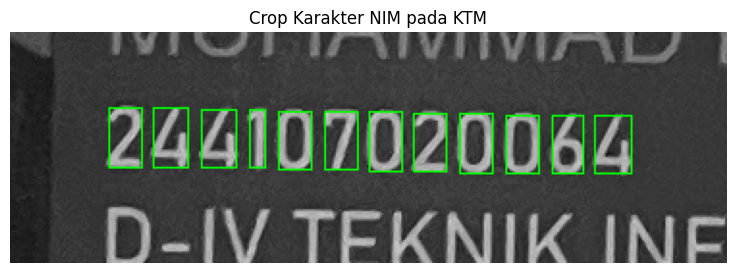

folder name: ktm no: 711777777711
NIM seharusnya : 244107020064
Akurasi karakter: 1 / 12


In [24]:
data_dir_testing = '/content/dataset/testing/ktm'
os.makedirs(data_dir_testing, exist_ok=True)

ktm_gray = cv2.cvtColor(ktm, cv2.COLOR_BGR2GRAY)
h, w = ktm_gray.shape
roi = ktm_gray[int(0.78 * h):int(0.90 * h), int(0.18 * w):int(0.42 * w)]
_, bw = cv2.threshold(roi, 150, 255, cv2.THRESH_BINARY)
cnts, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
boxes = [cv2.boundingRect(c) for c in cnts]
boxes = [b for b in boxes if b[1] > 30 and b[1] < 80 and b[3] > 15]
boxes = sorted(boxes, key=lambda b: b[0])
print('Jumlah karakter NIM terdeteksi:', len(boxes))

viz = cv2.cvtColor(roi, cv2.COLOR_GRAY2BGR)
for i, (x, y, bw_, bh_) in enumerate(boxes):
    cv2.rectangle(viz, (x, y), (x + bw_, y + bh_), (0, 255, 0), 1)
    char_img = roi[y:y + bh_, x:x + bw_]
    char_img = cv2.copyMakeBorder(char_img, 5, 5, 5, 5, cv2.BORDER_CONSTANT, value=0)
    cv2.imwrite(os.path.join(data_dir_testing, f'{i:02d}.png'), char_img)
plt.figure(figsize=(12, 3))
plt.imshow(cv2.cvtColor(viz, cv2.COLOR_BGR2RGB))
plt.title('Crop Karakter NIM pada KTM')
plt.axis('off')
plt.show()

model = tf.keras.models.load_model('/content/anpr.keras')
dirs  = pickle.load(open('/content/kelas.pickle', 'rb'))

temp = ''
for char_img in sorted(os.listdir(data_dir_testing)):
    img_array = cv2.imread(os.path.join(data_dir_testing, char_img), cv2.IMREAD_GRAYSCALE)
    new_array = cv2.resize(img_array, (width, height))
    new_array = new_array.reshape(-1, width, height, 1) / 255.0
    prediction = model.predict(new_array, verbose=0)
    temp += dirs[np.argmax(prediction[0])]
print('folder name: ktm no:', temp)
print('NIM seharusnya :', NIM)
print('Akurasi karakter:', sum(a == b for a, b in zip(temp, NIM)), '/', len(NIM))